In [195]:
# importing libraries

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

PROJECT_ROOT = Path.cwd().resolve().parent

TRAIN_PATH = PROJECT_ROOT / "data" / "processed" / "train_data.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training data exists:", TRAIN_PATH.exists())

Project root: /Users/mohdaakilkhan/Documents/Aakil_MAC/BITS_Mtech/BITS MTECH Learning/SEM-1/ML/2026AJ05523_ML_Assignment_2
Training data exists: True


In [196]:
# Load and validate the training data set
df = pd.read_csv(TRAIN_PATH)

TARGET = "Class"

FEATURES = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "AspectRation", "Eccentricity", "ConvexArea", "EquivDiameter",
    "Extent", "Solidity", "roundness", "Compactness",
    "ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4"
]

print("Training dataset shape:", df.shape)
print("Number of input features:", len(FEATURES))
print("Number of target classes:", df[TARGET].nunique())

assert all(col in df.columns for col in FEATURES + [TARGET])
assert len(FEATURES) == 16
assert df[TARGET].nunique() == 7

display(df.head())

Training dataset shape: (10834, 17)
Number of input features: 16
Number of target classes: 7


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,69471,1069.638,399.100245,225.005782,1.773733,0.825923,71088,297.410868,0.707386,0.977254,0.763027,0.745203,0.005745,0.001093,0.555328,0.985004,CALI
1,82877,1162.581,391.817013,270.836144,1.446694,0.722634,84171,324.841921,0.825986,0.984627,0.770544,0.829065,0.004728,0.001378,0.687349,0.994384,BARBUNYA
2,65042,1023.506,419.202858,198.962774,2.106941,0.880190,65748,287.774298,0.783403,0.989262,0.780231,0.686480,0.006445,0.000883,0.471255,0.992906,HOROZ
3,41315,758.920,287.438268,183.447580,1.566869,0.769858,41704,229.355383,0.791930,0.990672,0.901417,0.797929,0.006957,0.001740,0.636691,0.997611,SIRA
4,91088,1168.645,459.300729,253.950486,1.808623,0.833243,91799,340.553731,0.789051,0.992255,0.838119,0.741461,0.005042,0.000940,0.549765,0.994318,CALI


In [197]:
# Discriptive statistics of the training data set

summary = df[FEATURES].describe().T

summary["range"] = summary["max"] - summary["min"]
summary["skewness"] = df[FEATURES].skew()
summary["missing"] = df[FEATURES].isna().sum()

display(summary.round(4))

,count,mean,std,min,25%,50%,75%,max,range,skewness,missing
Area,10834.0,53017.5202,29355.8649,20420.0000,36275.7500,44606.5000,61427.2500,248424.0000,228004.0000,2.9367,0
Perimeter,10834.0,854.6360,214.4839,524.7360,703.0295,793.8805,975.9962,1895.9400,1371.2040,1.6244,0
MajorAxisLength,10834.0,319.7864,85.7217,183.6012,253.0731,296.5229,375.9044,726.3735,542.7723,1.3556,0
MinorAxisLength,10834.0,202.3239,45.0483,122.5127,175.8568,192.5340,217.0716,460.1985,337.6858,2.2403,0
AspectRation,10834.0,1.5809,0.2452,1.0249,1.4321,1.5496,1.7030,2.4303,1.4054,0.5901,0
Eccentricity,10834.0,0.7502,0.0919,0.2190,0.7158,0.7639,0.8094,0.9114,0.6925,-1.0675,0
ConvexArea,10834.0,53736.1198,29803.0519,20684.0000,36678.0000,45131.5000,62397.0000,251082.0000,230398.0000,2.9241,0
EquivDiameter,10834.0,252.9643,59.2740,161.2438,214.9133,238.3165,279.6634,562.4084,401.1647,1.9446,0
Extent,10834.0,0.7499,0.0487,0.5553,0.7188,0.7596,0.7868,0.8662,0.3109,-0.8844,0
Solidity,10834.0,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,0.0754,-2.6423,0


In [198]:
# Saving descriptive statistics 
summary.to_csv(
    FIGURE_DIR.parent / "descriptive_statistics.csv"
)

print("Descriptive statistics saved.")

Descriptive statistics saved.


In [199]:
# Analyse class distribution

class_counts = df[TARGET].value_counts()
class_percentages = df[TARGET].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(class_summary.round(2))

,Count,Percentage
Class,,
DERMASON,2837,26.19
SIRA,2109,19.47
SEKER,1621,14.96
HOROZ,1488,13.73
CALI,1304,12.04
BARBUNYA,1057,9.76
BOMBAY,418,3.86


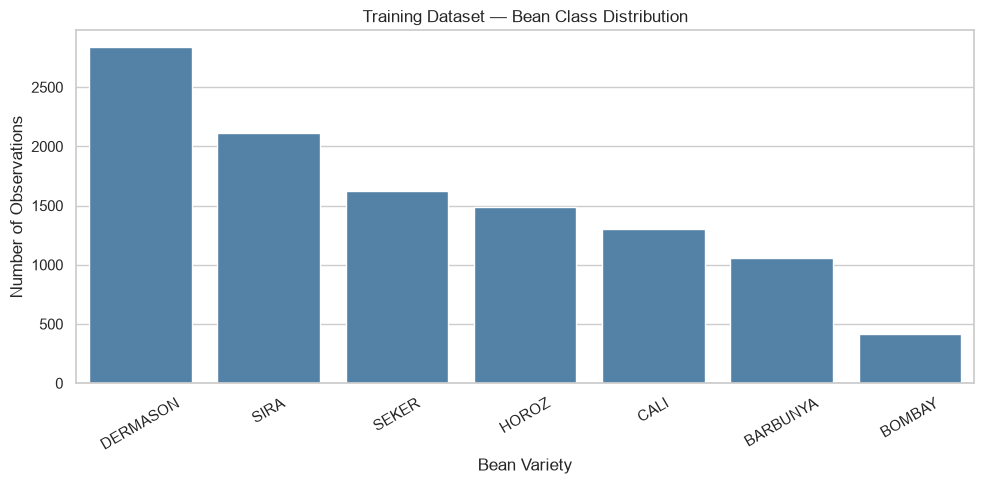

In [200]:
# Visualisation of the seven bean classes

fig, ax = plt.subplots(figsize=(10, 5))

order = df[TARGET].value_counts().index

sns.countplot(
    data=df,
    x=TARGET,
    order=order,
    color="steelblue",
    ax=ax
)

ax.set_title("Training Dataset — Bean Class Distribution")
ax.set_xlabel("Bean Variety")
ax.set_ylabel("Number of Observations")

plt.xticks(rotation=30)
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

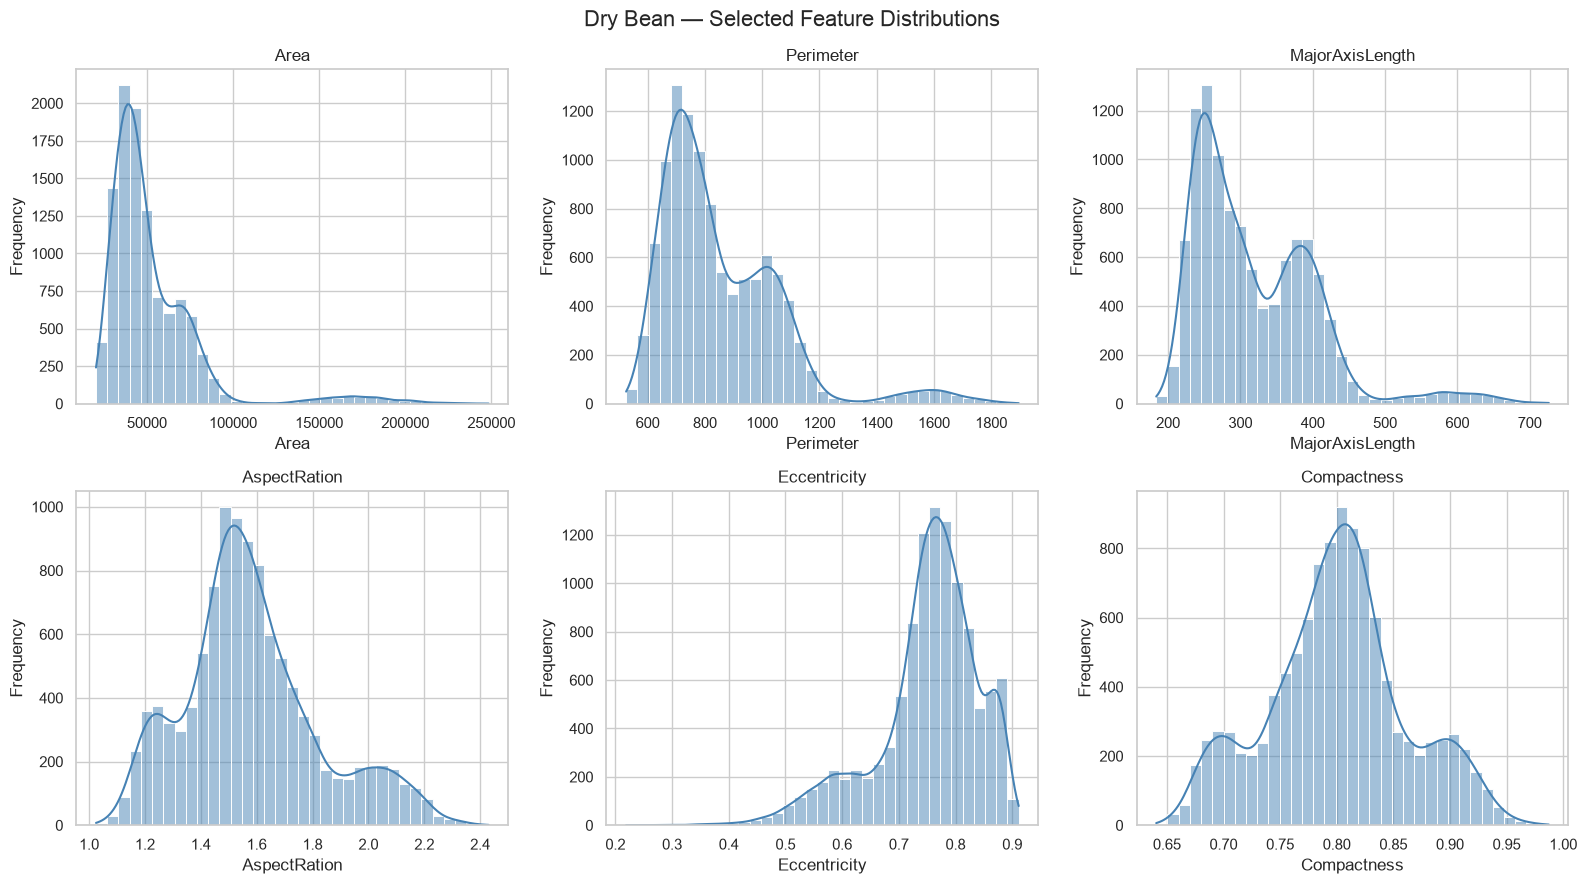

In [201]:
# feature distribution analysis

selected_features = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "AspectRation",
    "Eccentricity",
    "Compactness"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flatten(), selected_features):
    sns.histplot(
        df[feature],
        bins=35,
        kde=True,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Dry Bean — Selected Feature Distributions",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "feature_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [202]:
# skewness analysis of the features

skewness = df[FEATURES].skew().sort_values(ascending=False)

display(skewness.to_frame("Skewness").round(3))

print("Features with |skewness| > 1:")

display(
    skewness[skewness.abs() > 1]
)

,Skewness
Area,2.937
ConvexArea,2.924
MinorAxisLength,2.240
EquivDiameter,1.945
Perimeter,1.624
MajorAxisLength,1.356
AspectRation,0.590
ShapeFactor2,0.296
ShapeFactor3,0.242
Compactness,0.036


Features with |skewness| > 1:


Area               2.936712
ConvexArea         2.924108
MinorAxisLength    2.240298
EquivDiameter      1.944595
Perimeter          1.624442
MajorAxisLength    1.355629
Eccentricity      -1.067477
Solidity          -2.642263
ShapeFactor4      -2.824889
dtype: float64

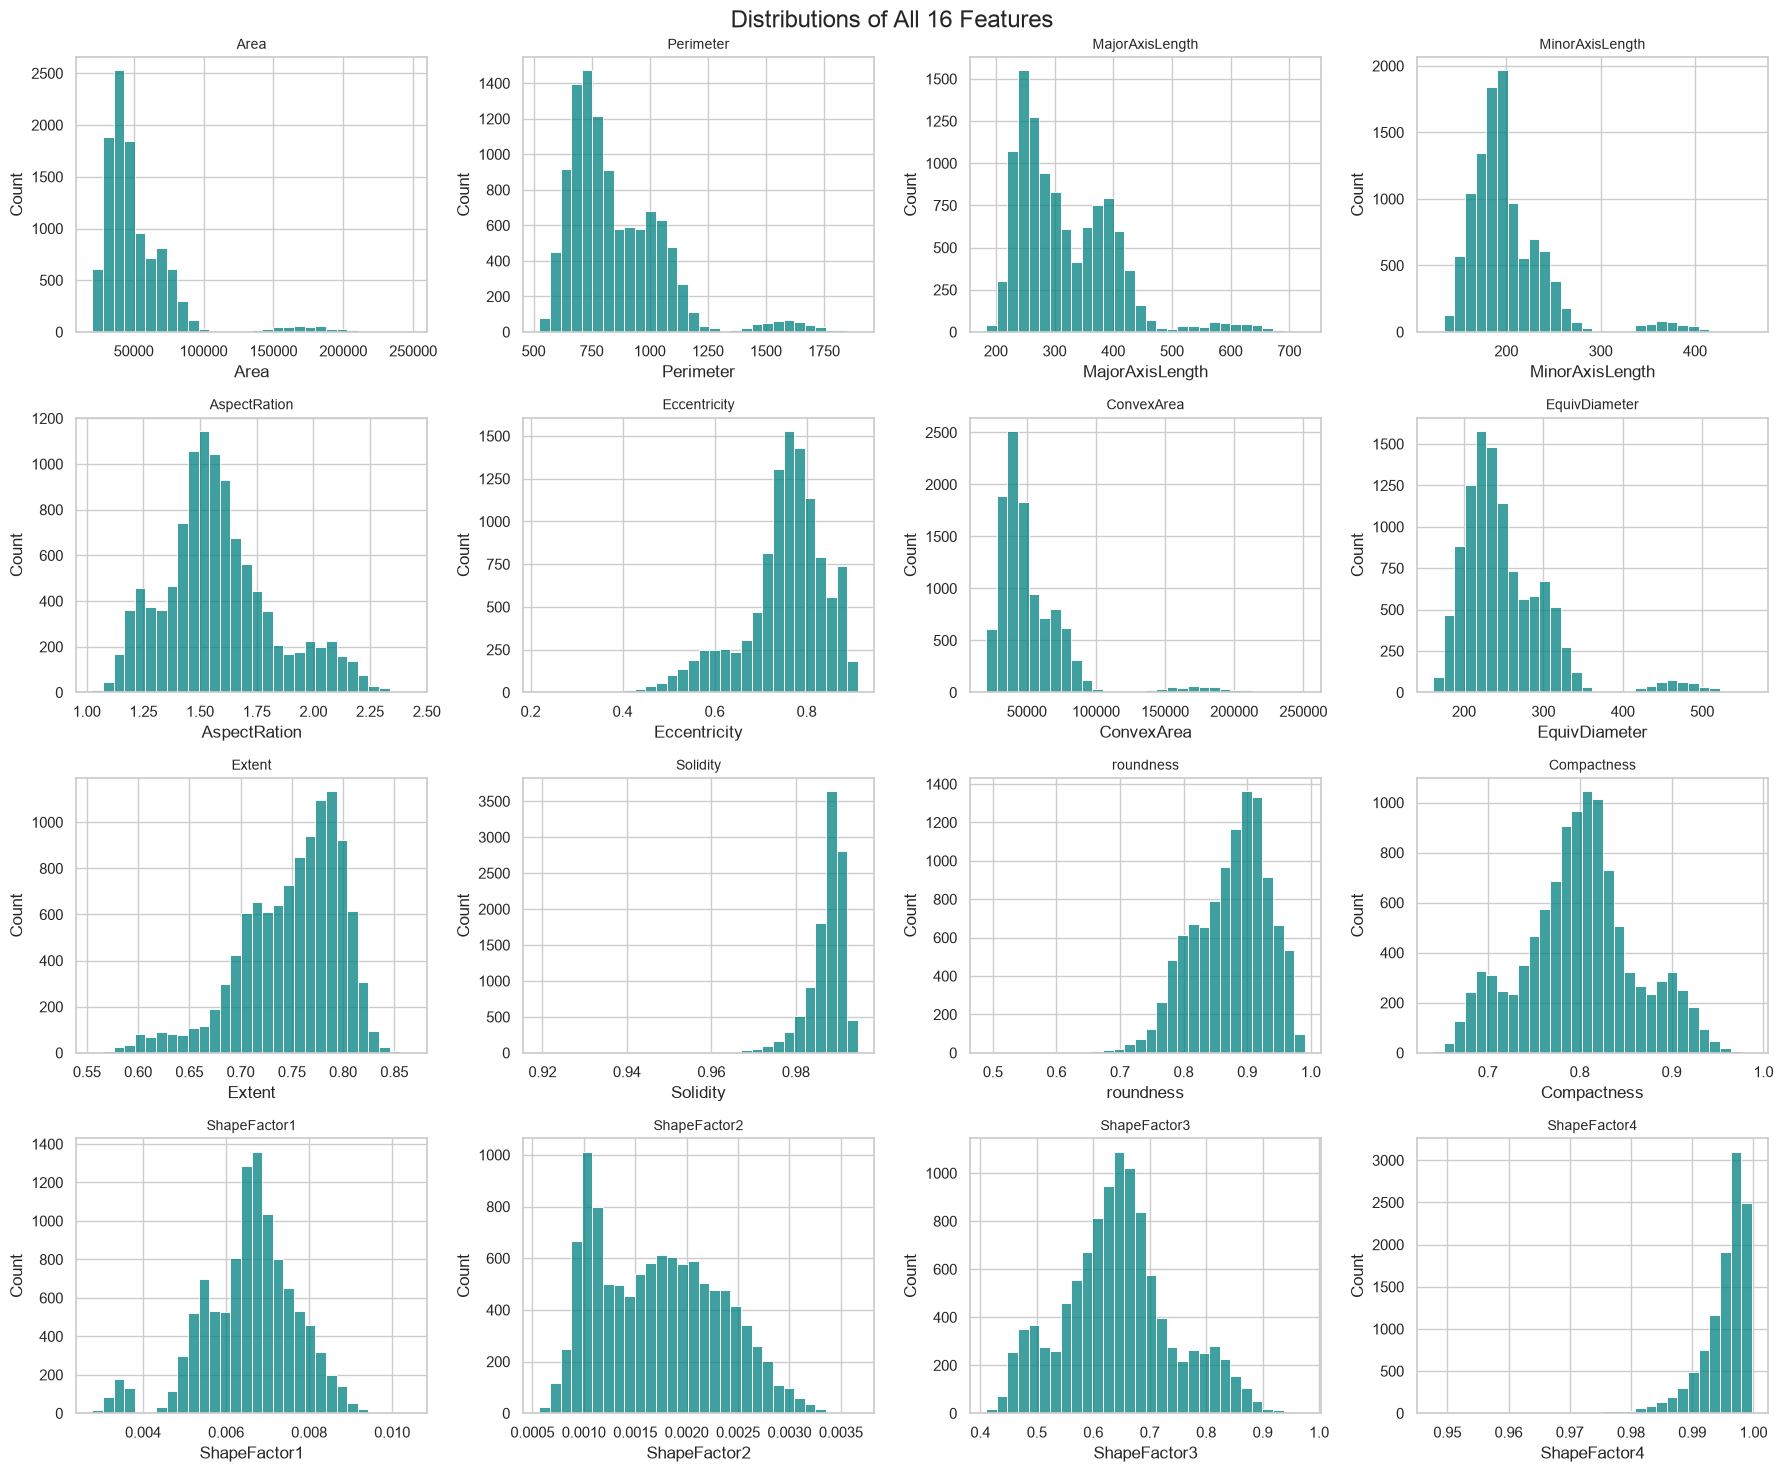

In [203]:
# plotting all the features
fig, axes = plt.subplots(4, 4, figsize=(18, 15))

for ax, feature in zip(axes.flatten(), FEATURES):
    sns.histplot(
        df[feature],
        bins=30,
        ax=ax,
        color="teal"
    )
    ax.set_title(feature, fontsize=10)

plt.suptitle("Distributions of All 16 Features", fontsize=17)
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "all_feature_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [204]:
# generating the correlation matrix

corr_matrix = df[FEATURES].corr(method="pearson")

display(corr_matrix.round(3))

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000,0.967,0.932,0.952,0.243,0.268,1.000,0.985,0.048,-0.193,-0.360,-0.269,-0.849,-0.641,-0.273,-0.351
Perimeter,0.967,1.000,0.978,0.914,0.387,0.392,0.968,0.992,-0.026,-0.301,-0.548,-0.408,-0.866,-0.769,-0.409,-0.425
MajorAxisLength,0.932,0.978,1.000,0.828,0.551,0.541,0.933,0.962,-0.082,-0.282,-0.598,-0.568,-0.776,-0.860,-0.568,-0.479
MinorAxisLength,0.952,0.914,0.828,1.000,-0.005,0.023,0.952,0.949,0.138,-0.153,-0.213,-0.019,-0.947,-0.475,-0.023,-0.260
AspectRation,0.243,0.387,0.551,-0.005,1.000,0.924,0.245,0.305,-0.366,-0.269,-0.769,-0.988,0.020,-0.837,-0.979,-0.452
Eccentricity,0.268,0.392,0.541,0.023,0.924,1.000,0.270,0.320,-0.319,-0.299,-0.726,-0.970,0.016,-0.859,-0.981,-0.450
ConvexArea,1.000,0.968,0.933,0.952,0.245,0.270,1.000,0.985,0.046,-0.203,-0.364,-0.271,-0.849,-0.643,-0.275,-0.358
EquivDiameter,0.985,0.992,0.962,0.949,0.305,0.320,0.985,1.000,0.022,-0.229,-0.438,-0.329,-0.894,-0.715,-0.332,-0.388
Extent,0.048,-0.026,-0.082,0.138,-0.366,-0.319,0.046,0.022,1.000,0.193,0.342,0.352,-0.134,0.239,0.346,0.152
Solidity,-0.193,-0.301,-0.282,-0.153,-0.269,-0.299,-0.203,-0.229,0.193,1.000,0.607,0.305,0.152,0.344,0.309,0.704


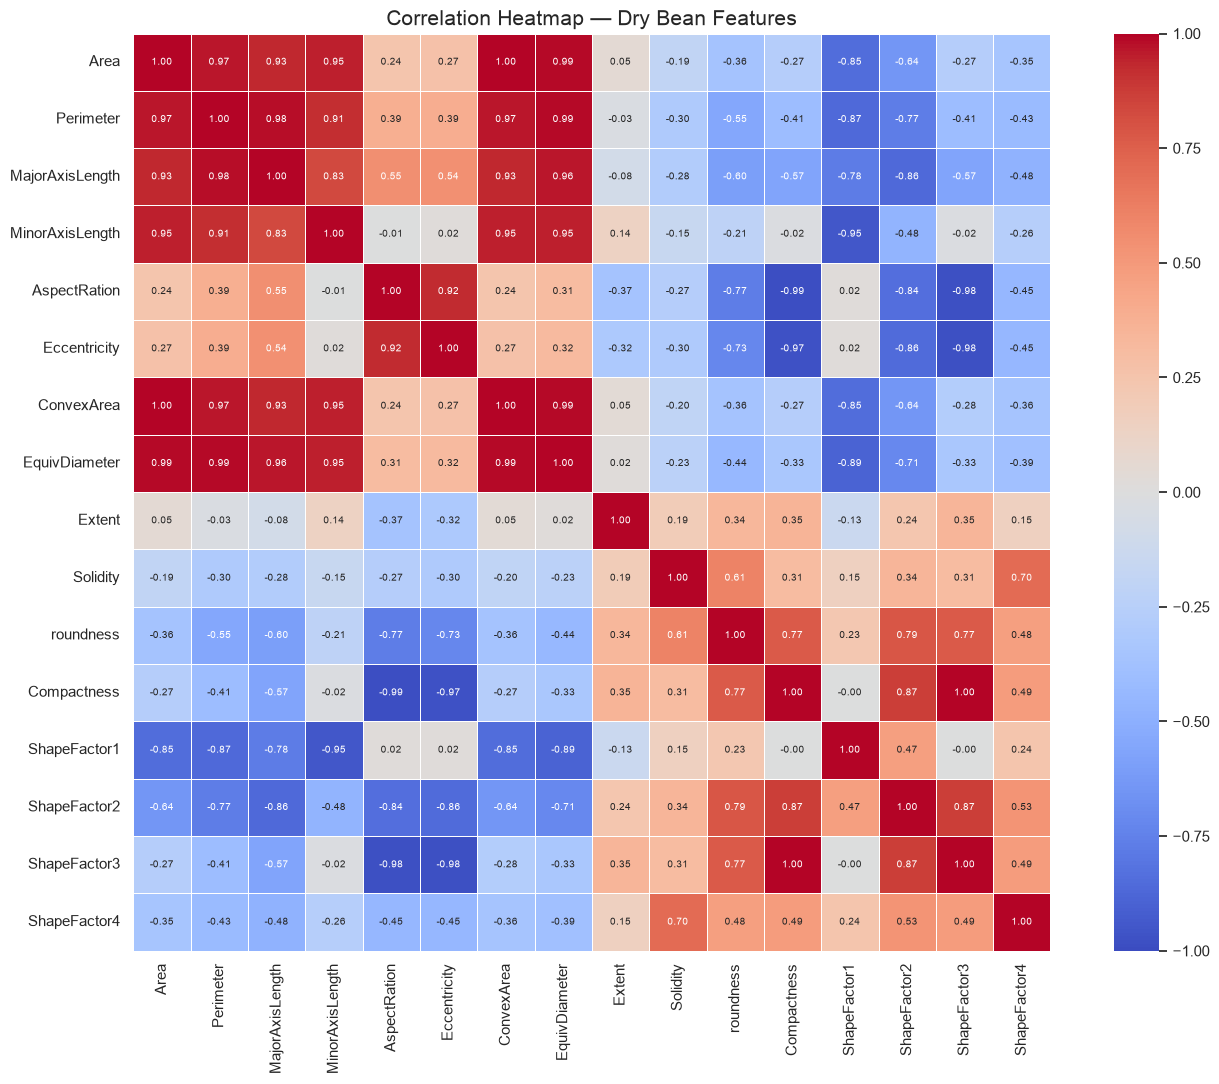

In [205]:
# generating the heatmap

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title(
    "Correlation Heatmap — Dry Bean Features",
    fontsize=15
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [206]:
# finding highly correlated features
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .rename("Correlation")
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() > 0.90
]

high_corr_pairs = high_corr_pairs.sort_values(
    "Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

display(high_corr_pairs)

,Feature 1,Feature 2,Correlation
6,Area,ConvexArea,0.999941
190,Compactness,ShapeFactor3,0.998682
23,Perimeter,EquivDiameter,0.991581
75,AspectRation,Compactness,-0.987644
103,ConvexArea,EquivDiameter,0.985364
7,Area,EquivDiameter,0.985077
94,Eccentricity,ShapeFactor3,-0.980988
78,AspectRation,ShapeFactor3,-0.978519
18,Perimeter,MajorAxisLength,0.977719
91,Eccentricity,Compactness,-0.970211


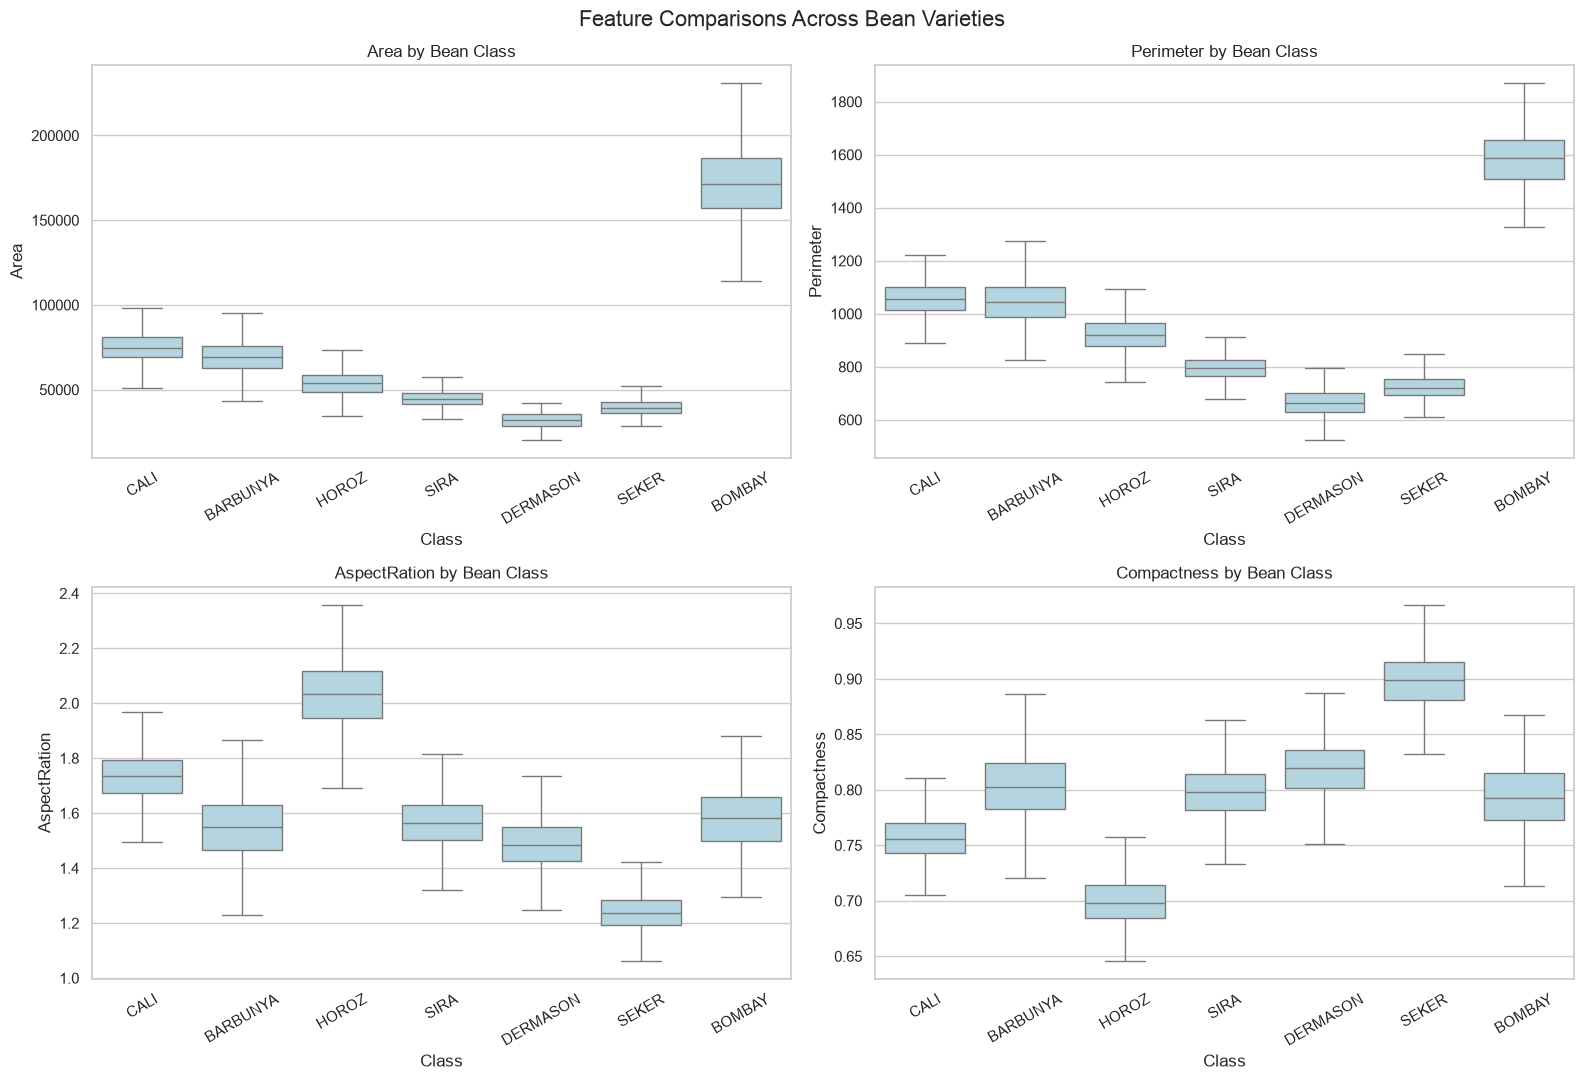

In [207]:
# boxplot by bean variety
comparison_features = [
    "Area",
    "Perimeter",
    "AspectRation",
    "Compactness"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, feature in zip(axes.flatten(), comparison_features):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature,
        ax=ax,
        color="lightblue",
        showfliers=False
    )

    ax.set_title(f"{feature} by Bean Class")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle(
    "Feature Comparisons Across Bean Varieties",
    fontsize=16
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "class_feature_boxplots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [208]:
# mean feature value by class

class_means = df.groupby(TARGET)[FEATURES].mean()

display(class_means.round(3))

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Class,,,,,,,,,,,,,,,,
BARBUNYA,69676.344,1045.014,369.882,239.959,1.546,0.755,70898.946,297.032,0.749,0.983,0.800,0.805,0.005,0.001,0.648,0.996
BOMBAY,173356.969,1585.060,592.450,374.554,1.583,0.770,175667.677,468.819,0.775,0.987,0.864,0.793,0.003,0.001,0.630,0.992
CALI,75410.623,1056.458,409.088,236.189,1.733,0.815,76560.483,309.263,0.759,0.985,0.846,0.757,0.005,0.001,0.573,0.991
DERMASON,32087.836,664.969,246.412,165.602,1.490,0.736,32468.405,201.588,0.753,0.988,0.908,0.819,0.008,0.002,0.672,0.997
HOROZ,53683.868,919.999,372.708,184.227,2.026,0.867,54474.158,260.813,0.706,0.986,0.795,0.701,0.007,0.001,0.492,0.992
SEKER,39851.783,727.074,251.166,201.871,1.245,0.585,40237.737,224.870,0.772,0.990,0.945,0.897,0.006,0.003,0.805,0.998
SIRA,44775.119,796.732,299.528,190.901,1.570,0.767,45318.726,238.454,0.749,0.988,0.885,0.797,0.007,0.002,0.636,0.995


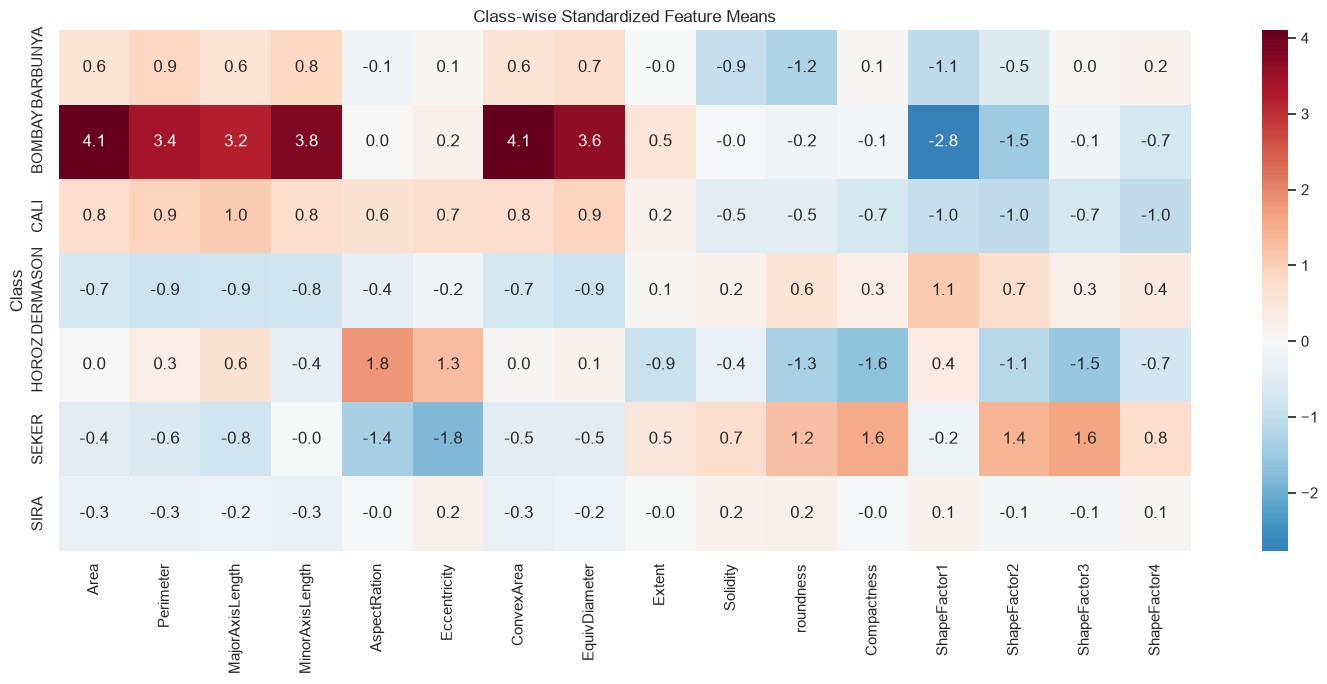

In [209]:
# Standardisation 
class_mean_scaled = (
    class_means - df[FEATURES].mean()
) / df[FEATURES].std().replace(0, np.nan)

fig, ax = plt.subplots(figsize=(15, 7))

sns.heatmap(
    class_mean_scaled,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    ax=ax
)

ax.set_title("Class-wise Standardized Feature Means")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "class_mean_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [210]:
# detecting the outliers

outlier_results = []

for feature in FEATURES:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    count = int(outlier_mask.sum())

    outlier_results.append({
        "Feature": feature,
        "Outlier Count": count,
        "Outlier Percentage": round(
            count / len(df) * 100, 2
        ),
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    "Outlier Percentage",
    ascending=False
)

display(outlier_df)

,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
5,Eccentricity,684,6.31,0.575405,0.949877
9,Solidity,621,5.73,0.979161,0.996530
15,ShapeFactor4,616,5.69,0.987485,1.004114
3,MinorAxisLength,457,4.22,114.034678,278.893784
0,Area,443,4.09,-1451.500000,99154.500000
6,ConvexArea,442,4.08,-1900.500000,100975.500000
12,ShapeFactor1,428,3.95,0.003841,0.009328
7,EquivDiameter,422,3.90,117.788143,376.788516
1,Perimeter,405,3.74,293.579375,1385.446375
4,AspectRation,403,3.72,1.025719,2.109416


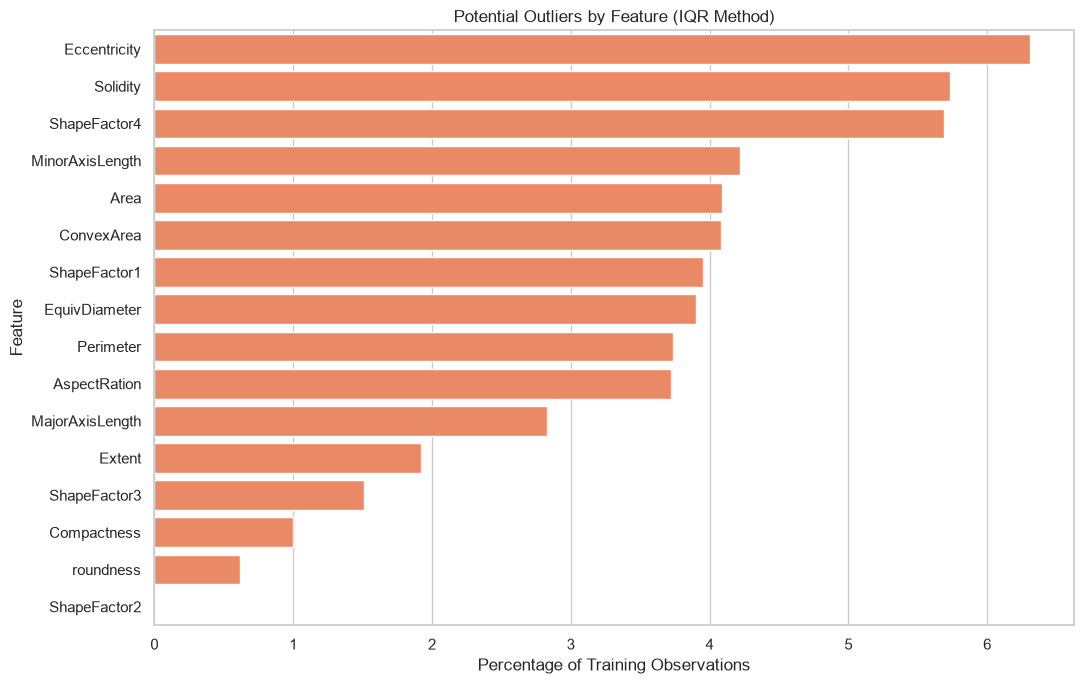

In [211]:
# Visualisation of the outlier percentage

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=outlier_df,
    x="Outlier Percentage",
    y="Feature",
    color="coral",
    ax=ax
)

ax.set_title("Potential Outliers by Feature (IQR Method)")
ax.set_xlabel("Percentage of Training Observations")
ax.set_ylabel("Feature")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "outlier_summary.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

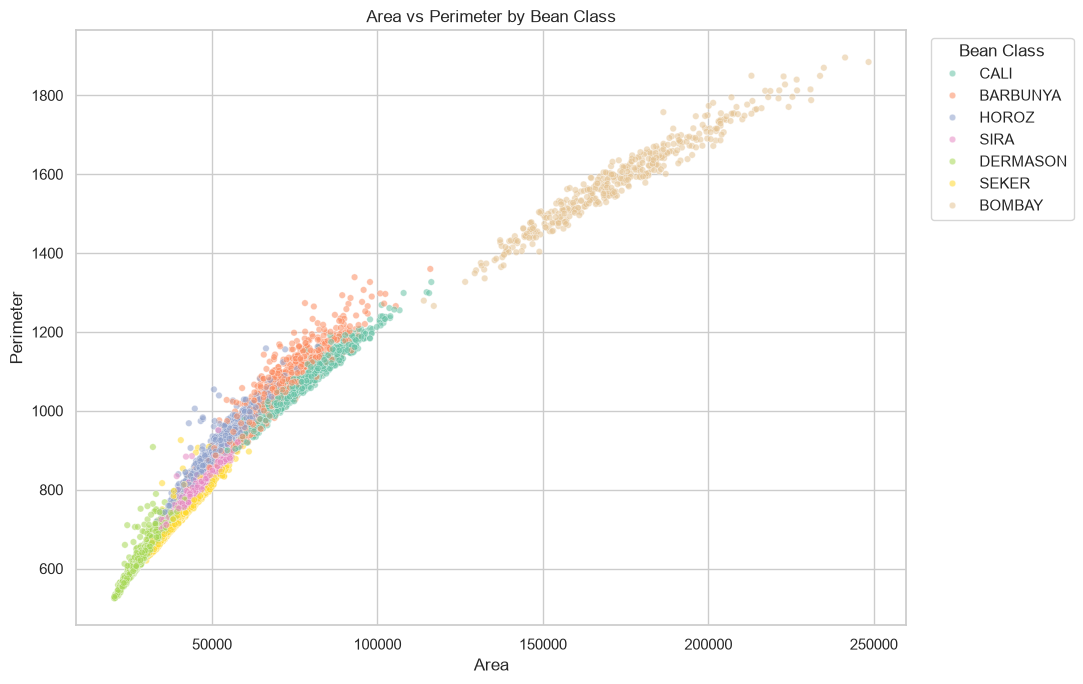

In [212]:
# investigation of the relatioship between features

fig, ax = plt.subplots(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="Area",
    y="Perimeter",
    hue=TARGET,
    alpha=0.55,
    s=22,
    ax=ax
)

ax.set_title("Area vs Perimeter by Bean Class")
ax.legend(
    title="Bean Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "area_vs_perimeter.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

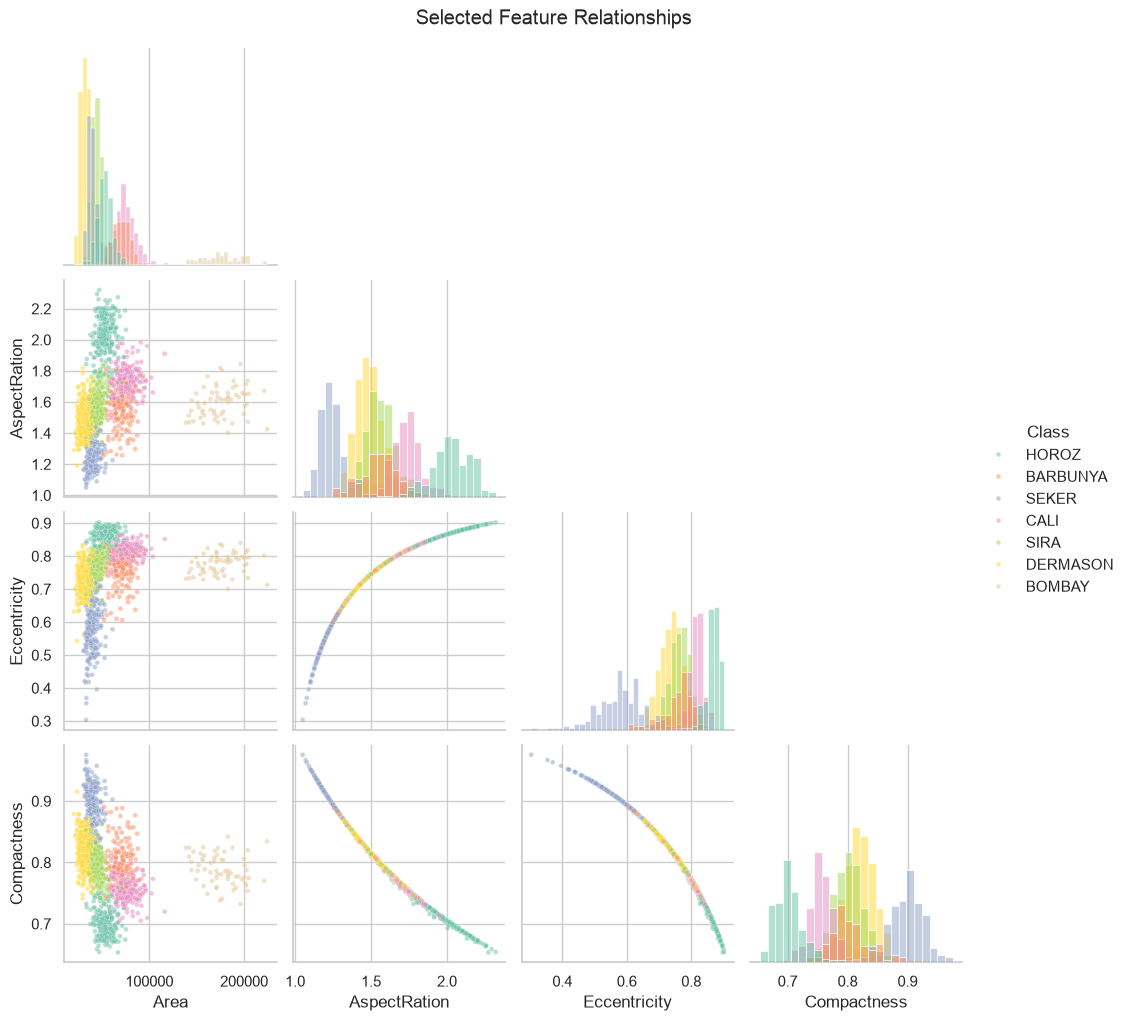

In [213]:
# pairplot of selected features

pair_features = [
    "Area",
    "AspectRation",
    "Eccentricity",
    "Compactness"
]

sample_df = df.sample(
    n=min(1500, len(df)),
    random_state=42
)

pair_grid = sns.pairplot(
    sample_df[pair_features + [TARGET]],
    hue=TARGET,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 12}
)

pair_grid.figure.suptitle(
    "Selected Feature Relationships",
    y=1.02
)

pair_grid.figure.savefig(
    FIGURE_DIR / "feature_pairplot.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [214]:
# compact EDA summary 
import json

eda_summary = {
    "training_rows": int(len(df)),
    "feature_count": len(FEATURES),
    "class_count": int(df[TARGET].nunique()),
    "missing_values": int(df.isna().sum().sum()),
    "class_distribution": {
        str(k): int(v)
        for k, v in df[TARGET].value_counts().items()
    },
    "high_correlation_pair_count": int(
        len(high_corr_pairs)
    ),
    "features_with_iqr_outliers": int(
        (outlier_df["Outlier Count"] > 0).sum()
    )
}

summary_path = PROJECT_ROOT / "reports" / "eda_summary.json"

with open(summary_path, "w") as file:
    json.dump(eda_summary, file, indent=4)

print(json.dumps(eda_summary, indent=4))

{
    "training_rows": 10834,
    "feature_count": 16,
    "class_count": 7,
    "missing_values": 0,
    "class_distribution": {
        "DERMASON": 2837,
        "SIRA": 2109,
        "SEKER": 1621,
        "HOROZ": 1488,
        "CALI": 1304,
        "BARBUNYA": 1057,
        "BOMBAY": 418
    },
    "high_correlation_pair_count": 21,
    "features_with_iqr_outliers": 15
}


## EDA Findings — Dry Bean Classification

### 1. Dataset Structure

The training dataset contains [number] observations, 16 numerical input features and seven bean varieties.

### 2. Class Distribution

The most frequent class is [class] and the least frequent class is [class].

The class distribution indicates [degree of imbalance]. Macro-averaged evaluation metrics will therefore be useful.

### 3. Feature Distributions

The most strongly skewed features include [features].

Feature scales vary substantially, suggesting that standardization will be important for Logistic Regression, KNN and SVM.

### 4. Correlation Analysis

Strongly correlated feature pairs include [feature pairs].

These relationships may indicate redundant geometric measurements. Feature selection will be considered during model experimentation.

### 5. Class-wise Comparisons

The features [features] appear particularly useful for distinguishing bean varieties.

Some class distributions overlap, suggesting that multiple features may be needed for accurate classification.

### 6. Outlier Analysis

The features with the highest proportions of IQR-flagged observations are [features].

Outliers will be retained for the initial baseline models because they may represent valid bean characteristics.

### 7. Modeling Implications

The next stage will implement training-only preprocessing, including numerical imputation and feature scaling.

All five models will use the same stratified training/test split. The held-out test set will remain untouched until final evaluation.
